# Starter Code


In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Set default styles for our plots
sns.set_theme("notebook")

In [88]:
df = pd.read_csv("./data/house_price_regression_dataset.csv")

## Simple Linear Regression from Scratch


### Manual Implementation

1. **Prediction Function**: Calculates $f(x) = wx + b$.
2. **Cost Function**: Measures how far off our predictions are (Mean Squared Error).
3. **Gradient Descent**: The optimizer that adjusts weights ($w$) and bias ($b$) to minimize the cost.


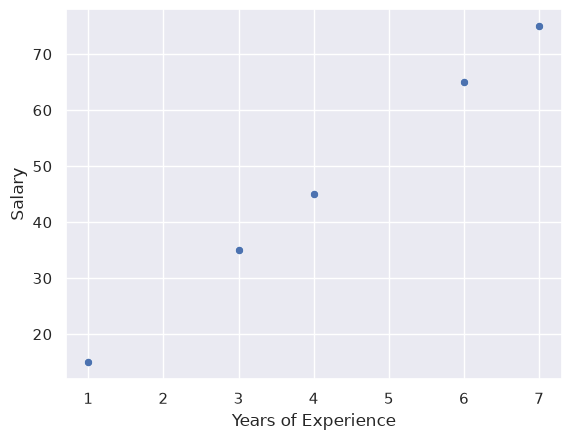

In [89]:
X = np.array([1, 3, 4, 6, 7.0])  #! feature: years of experience
y = np.array([15, 35, 45, 65, 75])  #! Target: salary (in thousands)

m = X.shape[0]

w = 1
b = 0

sns.scatterplot(x=X, y=y)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

### Prediction Function


In [90]:
def make_prediction(X, w, b):
    pred = np.zeros((m,))
    for i in range(m):
        pred[i] = w * X[i] + b  #! ŷ = wx + b
    return pred


# display(make_prediction(X, w, b))

### Cost Function


In [91]:
def compute_cost(X, y, w, b):
    cost = 0.0
    error = make_prediction(X, w, b) - y  #! (ŷ - y)
    cost = +(error**2)
    return cost.sum() / (2 * m)  #! Σ error²/2m


print(compute_cost(X, y, w, b))

1100.6


### Calculate Gradient (Derivatives)


In [92]:
def calculate_gradient(X, y, w, b):
    dj_dw = 0
    dj_db = 0
    pred = make_prediction(X, w, b)
    err = pred - y
    dj_dw += err * X
    dj_db += err
    return dj_dw.sum() / m, dj_db.sum() / m


print(calculate_gradient(X, y, w, b))

(np.float64(-220.8), np.float64(-42.8))


### Gradient Descent Algorithm


In [93]:
def gradient_descent(X, y, w_input, b_input, max_iter, alpha=0.01):
    """Automates the tuning of w and b to minimize cost"""

    cost_memo = []
    iteration = []

    w = w_input
    b = b_input
    for i in range(max_iter):
        dj_dw, dj_db = calculate_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        cost = compute_cost(X, y, w, b)
        cost_memo.append(cost)
        iteration.append(i)

        if i % 100 == 0:
            print(
                f"Iteration {i:^7d} Cost : {cost:^8.4f}  w : {w:^8.4f}  b : {b:^8.4f}"
            )

    return w, b, cost_memo, iteration

### Training the Model

- Initialize the **weights ($w$) & bias ($b$)** to **0.0**
- Run the **Gradient Descent** algorithm for many iterations to find out optimal weights **($w$)** and bias **($b$)** that minimize the cost.


In [94]:
w_best, b_best, cost_memo, iter_list = gradient_descent(
    X,
    y,
    w_input=0,
    b_input=0,
    max_iter=6000,
    alpha=0.01,
)
print(f"w : {w_best:.2f} b : {b_best:.2f}")

Iteration    0    Cost : 790.3717  w :  2.4300   b :  0.4700 
Iteration   100   Cost :  0.6120   w : 10.4659   b :  2.5593 
Iteration   200   Cost :  0.4115   w : 10.3821   b :  2.9986 
Iteration   300   Cost :  0.2767   w : 10.3133   b :  3.3588 
Iteration   400   Cost :  0.1861   w : 10.2569   b :  3.6542 
Iteration   500   Cost :  0.1251   w : 10.2107   b :  3.8965 
Iteration   600   Cost :  0.0841   w : 10.1727   b :  4.0951 
Iteration   700   Cost :  0.0566   w : 10.1416   b :  4.2580 
Iteration   800   Cost :  0.0380   w : 10.1162   b :  4.3915 
Iteration   900   Cost :  0.0256   w : 10.0952   b :  4.5010 
Iteration  1000   Cost :  0.0172   w : 10.0781   b :  4.5909 
Iteration  1100   Cost :  0.0116   w : 10.0640   b :  4.6645 
Iteration  1200   Cost :  0.0078   w : 10.0525   b :  4.7249 
Iteration  1300   Cost :  0.0052   w : 10.0431   b :  4.7744 
Iteration  1400   Cost :  0.0035   w : 10.0353   b :  4.8150 
Iteration  1500   Cost :  0.0024   w : 10.0290   b :  4.8483 
Iteratio

## Multiple Linear Regression

Main Formula

- ŷ = (W · X) + b
- ŷ = w₁x₁ + w₂x₂ + w₃x₃ + ... + wₙxₙ + b
  - W · X = w₁×x₁ + w₂×x₂ + w₃×x₃ + w₄×x₄
    - W = [w₁, w₂, w₃, w₄]
    - X = [x₁, x₂, x₃, x₄]

- J(W, b) = (1/(2m)) × Σ (ŷᵢ - yᵢ)²


In [95]:
W_init = np.ones((5,))

W_init.ravel()

array([1., 1., 1., 1., 1.])

##

- m = ডেটা পয়েন্টের সংখ্যা (কতগুলো রো আছে)
- n = ফিচারের সংখ্যা (ইনপুট কলাম কয়টি)
- এই ডেটাসেটে: মোট ডেটা পয়েন্ট = ৫টি (একটি টেবিলের ৫টি সারি)
- ফিচার সংখ্যা = ৪টি (পিএস স্কিল, পস টাইম, জিপিএ, এক্সপেরিয়েন্স)
  - টার্গেট কলাম = ১টি (স্যালারি)
  * ds
